# Kinematical X-ray Scattering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/08-xray_diffraction/01-kinematical_xray.ipynb)

In this example the static X-ray diffraction of a thin SrRuO$_3$ film on a SrTiO$_3$ substrate is calculated by the kinematical X-ray scattering formalism of {py:class}`XrayKin <udkm1Dsim.simulations.scattering.kinematical.XrayKin>`, see the [scattering overview](#example_scattering_overview) for all formalisms.

:::{admonition} Reference {cite}`warren1990`
:class: seealso
B. E. Warren, *X-Ray Diffraction*, Dover Publications, New York (1990)
:::

:::{note}
The kinematical approximation is only valid for thin or imperfect crystals for which multiple scattering can be neglected.
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

try:
    plt.style.use(["mbistyles.base", "mbistyles.paper"])  # matplotlib styles of the MBI
except OSError:
    pass  # mbistyles is not installed, the default matplotlib style is used

## Structure

Refer to the [structure example](#example_structure) for more details.

In [2]:
O = ud.Atom("O")
Ti = ud.Atom("Ti")
Sr = ud.Atom("Sr")
Ru = ud.Atom("Ru")
Pb = ud.Atom("Pb")
Zr = ud.Atom("Zr")

In [3]:
# c-axis lattice constants of the two layers
c_STO_sub = 3.905 * u.angstrom
c_SRO = 3.94897 * u.angstrom

# SRO layer
SRO = ud.UnitCell(
    "SRO",
    "Strontium Ruthenate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_SRO),
    thermal=ud.ThermalParameters(
        therm_cond=5.72 * u.W / (u.m * u.K),
        lin_therm_exp=1.03e-5,
        heat_capacity="455.2 + 0.112*T - 2.1935e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=6.312 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.44 + 4.32j)),
)
SRO.add_atom(O, 0)
SRO.add_atom(Sr, 0)
SRO.add_atom(O, 0.5)
SRO.add_atom(O, 0.5)
SRO.add_atom(Ru, 0.5)

# STO substrate
STO_sub = ud.UnitCell(
    "STOsub",
    "Strontium Titanate Substrate",
    lattice=ud.LatticeParameters(c_axis=c_STO_sub),  # a- and b-axis default to the c-axis
    thermal=ud.ThermalParameters(
        therm_cond=12 * u.W / (u.m * u.K),
        lin_therm_exp=1e-5,
        heat_capacity="733.73 + 0.0248*T - 6.531e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=7.800 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.1 + 0j)),
)
STO_sub.add_atom(O, 0)
STO_sub.add_atom(Sr, 0)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(Ti, 0.5)

In [4]:
S = ud.Structure("Single Layer")
S.add_sub_structure(SRO, 200)  # add 200 layers of SRO to sample
S.add_sub_structure(STO_sub, 1000)  # add 1000 layers of STO substrate

## Kinematical X-ray Simulation

The {py:class}`XrayKin <udkm1Dsim.simulations.scattering.kinematical.XrayKin>` simulation is initialized as all other simulations, see the [scattering overview](#example_scattering_overview) for its experiment parameters and polarizations.

In [5]:
kin = ud.XrayKin(S, True)
kin.disp_messages = True
kin.save_data = False
kin

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,True
energy,not set
wavelength,not set
wavenumber,not set
theta,[0] deg
q_z,[0] 1/nm


## Homogeneous X-ray scattering

The kinematical theory can only be applied to homogeneous samples which renders it very useful for static simulations.

### $q_z$-scan

The reflectivity has a first dimension for the photon energies and a second for the scattering vectors $q_z$, see the experiment parameters in the [scattering overview](#example_scattering_overview).

In [6]:
kin.energy = 8047 * u.eV
kin.qz = np.r_[3.1:3.3:0.00001] / u.angstrom  # qz range

res_hom = kin.homogeneous_reflectivity()  # this is the actual calculation

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.009426 s


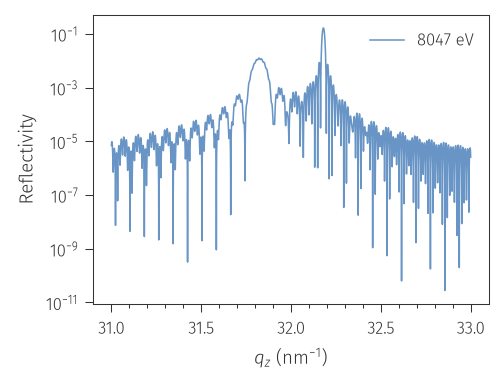

In [7]:
plt.figure()
plt.semilogy(res_hom.qz[0, :], res_hom.R[0, :], label=f"{res_hom.quantity('energy')[0]}")
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.legend()
plt.show()

### Instrument Function

The angular resolution of the experiment is included by the instrument of the simulation, see the [instrument function example](#example_instrument_function).
Here, a Gaussian angular resolution of 0.03° (FWHM), i.e. about 0.004 Å$^{-1}$ in $q_z$ at the Bragg peaks, is convolved on the dense grid of the experiment, which takes a single calculation.

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.024392 s


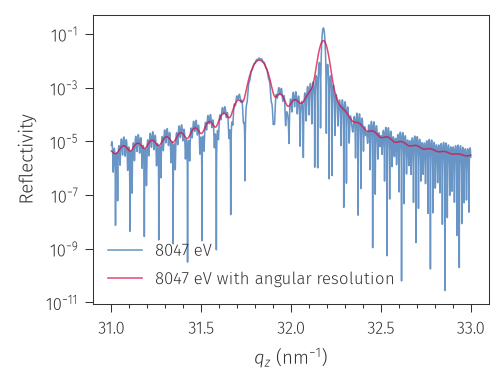

In [8]:
kin.instrument.theta_resolution = "gauss"
kin.instrument.theta_width = 0.03 * u.deg
kin.instrument.theta_mode = "convolution"
res_instrument = kin.homogeneous_reflectivity()

plt.figure()
plt.semilogy(res_hom.qz[0, :], res_hom.R[0, :], label=f"{res_hom.quantity('energy')[0]}")
plt.semilogy(
    res_instrument.qz[0, :],
    res_instrument.R[0, :],
    label=f"{res_instrument.quantity('energy')[0]} with angular resolution",
)
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.legend()
plt.show()

## Widget

The {py:meth}`homogeneous_reflectivity <udkm1Dsim.simulations.scattering.kinematical.XrayKin.homogeneous_reflectivity>` method is so fast, it is possible to build some fancy widgets, e.g. for visual data fitting.

:::{attention}
In order to get the widget to work in Jupyter, you should install the following packages which are not a dependency of the **udkm1Dsim** toolbox

    pip install ipympl ipywidgets

or

    conda install ipympl ipywidgets
:::

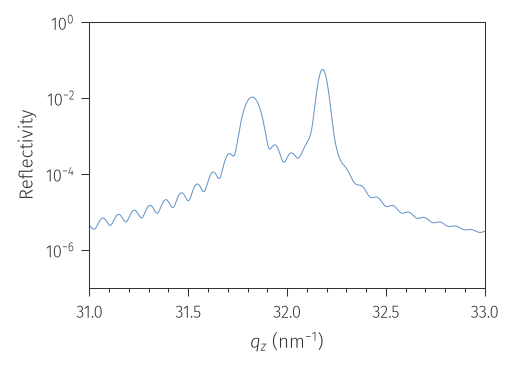

In [9]:
%matplotlib widget

from IPython.display import display
from ipywidgets import FloatSlider, IntSlider, VBox

kin.disp_messages = False
kin.qz = np.r_[3.1:3.3:0.0001] / u.angstrom  # qz range
res_hom = kin.homogeneous_reflectivity()

fig, ax = plt.subplots(figsize=(3.4, 2.3))
line = ax.semilogy(res_hom.qz[0, :], res_hom.R[0, :], lw=0.5)[0]
ax.set_ylabel("Reflectivity")
ax.set_xlabel("$q_z$ (nm$^{-1}$)")
ax.set_ylim(1e-7, 1)
ax.set_xlim(31, 33)

# sliders
SRO_caxis = FloatSlider(
    value=3.94897,
    min=3.85,
    max=4.05,
    step=0.001,
    description="SRO c-axis (Å)",
    style={"description_width": "initial"},
)
SRO_num = IntSlider(
    value=150,
    min=0,
    max=1000,
    description="# SRO Unit Cells",
    style={"description_width": "initial"},
)
FWHM = FloatSlider(
    value=0.03,
    min=0.001,
    max=0.1,
    step=0.001,
    readout_format=".3f",
    description="FWHM (deg)",
    style={"description_width": "initial"},
)


def update(change):
    SRO.c_axis = SRO_caxis.value * u.angstrom
    S.sub_structures[0][1] = SRO_num.value
    kin.instrument.theta_width = FWHM.value * u.deg
    res_hom = kin.homogeneous_reflectivity()
    line.set_ydata(res_hom.R[0, :])
    fig.canvas.draw_idle()


SRO_caxis.observe(update, names="value")
SRO_num.observe(update, names="value")
FWHM.observe(update, names="value")

display(
    VBox(
        [SRO_caxis, SRO_num, FWHM],
        justify_content="space-between",
        border="solid 2px",
    )
)

plt.show()

## Gallery Plot

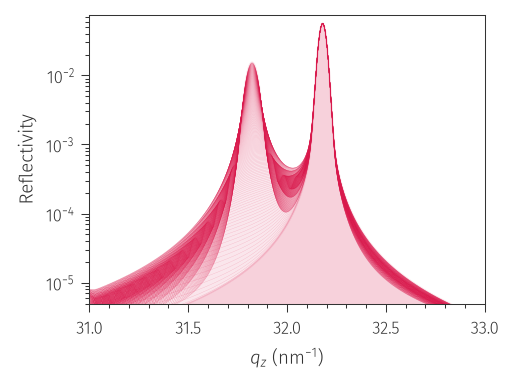

In [10]:
kin.instrument.theta_width = 0.03 * u.deg

plt.figure()
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylim(5e-6, 0.75e-1)
plt.xlim(31, 33)

S.sub_structures[0][1] = 250
res_hom = kin.homogeneous_reflectivity()
plt.fill(res_hom.qz[0, :], res_hom.R[0, :], alpha=0.1, color="#D71045")

S.sub_structures[0][1] = 0
res_hom = kin.homogeneous_reflectivity()
plt.fill(res_hom.qz[0, :], res_hom.R[0, :], alpha=0.1, color="#D71045")

for n in range(250):
    S.sub_structures[0][1] = n
    res_hom = kin.homogeneous_reflectivity()
    plt.semilogy(res_hom.qz[0, :], res_hom.R[0, :], lw=0.2, alpha=0.2, color="#D71045")

plt.show()